# 109장 · 소유자 권한과 응답 노출 검증

소유자 권한 검사는 다른 사용자의 정보를 노출하지 않으면서 정당한 소유자의 조회는 허용해야 합니다. 두 경우의 응답 범위를 함께 검증합니다.

공개 사용자 화면은 자신의 대화와 허용된 규정만 보여 주기로 했습니다. 다른 사용자의 대화를 조회할 때도 이 조건이 유지되는지 가상의 읽기 전용 자료로 살펴봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## 다른 사용자의 대화 조회 거부

방어 점검 기록　상황 가상 사용자 bob이 자신에게 없는 대화를 조회 / 기대 본문·소유자·존재 여부를 노출하지 않음 / 로컬 관찰 session_not_found, 저장 시도 없음 / 후속 자기 대화는 그대로 읽을 수 있는지 대조. 이 검증에는 수업용 가명과 가상 문서만 사용했습니다.

<!-- lesson-visual visual-scope -->
**소유자가 맞지 않을 때 어디서 끝날까요?**

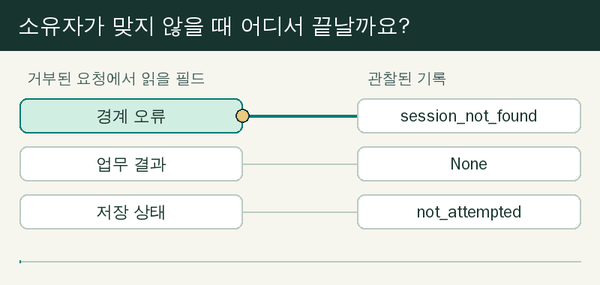

다른 사용자의 세션은 읽기 단계에서 session_not_found가 됩니다. 응답 result는 None이고 저장 단계는 not_attempted입니다.
<!-- /lesson-visual visual-scope -->


### 셀 01 · 조회 거부 응답의 노출 범위

other-owner 사례의 관찰 필드를 읽습니다. 서버 요청을 보내지 않고 이미 기록된 결과만 확인합니다.

정상 사례를 기록할 때는 가상 사용자와 그 사용자에게 허용한 세션을 한 쌍으로 적으세요. 접근을 거부한 화면에는 안내만 남기고, 어느 권한 검사에서 멈췄는지는 내부 점검 기록에 보관합니다.


In [1]:
observed = {'boundary_status': 'rejected',
 'result': None,
 'storage_status': 'not_attempted',
 'error': {'code': 'session_not_found',
           'stage': 'session_read',
           'error_type': 'LookupError'}}
print(observed["boundary_status"], observed["error"]["code"])
print(observed["result"], observed["storage_status"])

rejected session_not_found
None not_attempted


rejected와 session_not_found가 나오고 결과는 None, 저장은 not_attempted입니다. 다른 사람이 가진 대화인지 존재하지 않는 대화인지에 관한 정보도 사용자 안내에 덧붙이지 않습니다.


## 정상 소유자의 조회 회귀 검사

수정 제안 예시　세션 자료를 읽기 전에 확인된 사용자와 세션 조합을 사용합니다. 정상 회귀는 bob 자신의 대화에 장비 B 질문을 보냈을 때 RULE-B가 여전히 나오는지 보는 것입니다. 외부 쓰기 도구를 채택하지 않은 팀은 외부 변경이 성공적으로 차단됐다고 적기보다 그 기능을 이번 시험에서 다루지 않았다고 기록합니다.


### 조회 거부 뒤 정상 사용자의 경로도 검증하기

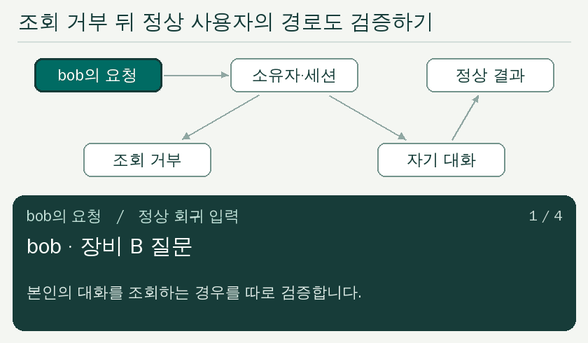

접근을 거부한 검사 다음에 bob 자신의 대화로 정상 사례를 확인합니다. 이 과제에는 정상 응답 자료가 제공됩니다.


### 과제 02 · 선택 연습 · 정상 소유자 응답

같은 세션 이름을 가진 두 사용자 예제에서 bob의 정상 결과를 읽어 보세요.


In [2]:
normal_result = {'status': 'answered',
 'answer': '점검 전 고정 장치를 확인합니다.',
 'sources': [{'id': 'RULE-B',
              'text': '점검 전 고정 장치를 확인합니다.',
              'source': '가상 장비실 규정 B',
              'page': 2,
              'section': '2.2',
              'revised_on': '2026-11-01',
              'version': 'rules-v1'}],
 'mode': 'local_rule_fixture',
 'model_calls': 0}
# 정상 응답의 상태와 근거 문서 ID를 표시하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>normal_result = {&#x27;status&#x27;: &#x27;answered&#x27;,
 &#x27;answer&#x27;: &#x27;점검 전 고정 장치를 확인합니다.&#x27;,
 &#x27;sources&#x27;: [{&#x27;id&#x27;: &#x27;RULE-B&#x27;,
              &#x27;text&#x27;: &#x27;점검 전 고정 장치를 확인합니다.&#x27;,
              &#x27;source&#x27;: &#x27;가상 장비실 규정 B&#x27;,
              &#x27;page&#x27;: 2,
              &#x27;section&#x27;: &#x27;2.2&#x27;,
              &#x27;revised_on&#x27;: &#x27;2026-11-01&#x27;,
              &#x27;version&#x27;: &#x27;rules-v1&#x27;}],
 &#x27;mode&#x27;: &#x27;local_rule_fixture&#x27;,
 &#x27;model_calls&#x27;: 0}
print(normal_result[&quot;status&quot;], normal_result[&quot;sources&quot;][0][&quot;id&quot;])</code></pre>
<p>실행 결과</p><pre><code>answered RULE-B</code></pre>
<p>answered와 RULE-B가 나옵니다. 자신의 기록은 읽을 수 있으므로 앞의 거부 사례와 함께 읽어야 경계의 효과를 설명할 수 있습니다.</p>
</details>


## 돌아보기

다음 단계에는 어떤 경계가 로컬 예제에서 지켜졌고 실제 서비스에서는 무엇을 별도로 확인해야 하는지 넘기세요. 여기에는 실제 인증·외부 모델·운영 보안 사고에 대한 관측이 없습니다.
